# 01 — Exploratory data analysis

Goal: understand the labels, the MiewID global descriptors and the SIFT keypoints well enough
to choose models and a validation scheme. Uses only allowed libraries (numpy, pandas, scipy,
scikit-learn, opencv for matching provided keypoints, matplotlib). **No images are read**
(decision D-005).

Run from the repo root or from `notebooks/`; data is expected in `projectwild3/` (D-004).
Sections:
1. Labels: species, identities, viewpoints
2. MiewID descriptors: norms, PCA, same- vs different-identity similarity
3. Retrieval baseline (leave-one-out on train) and the `new_individual` problem
4. Test vs train: how "known" do test images look?
5. SIFT keypoints: counts, layout, and how well matching separates identities
6. Takeaways and models to try

In [1]:
import os, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
import cv2

ROOT = Path.cwd() if (Path.cwd() / 'projectwild3').exists() else Path.cwd().parent
D = ROOT / 'projectwild3'
DM = D / 'reid_student_data_main'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
COL = {'hyena': '#c2185b', 'leopard': '#f9a825'}
rng = np.random.default_rng(0)

train = pd.read_csv(DM / 'train.csv'); test = pd.read_csv(DM / 'test.csv')
ids = pd.read_csv(DM / 'miewid_ids.csv').id.values
X = np.load(DM / 'miewid_features.npy')
row = {k: i for i, k in enumerate(ids)}
Xtr = X[[row[i] for i in train.id]]; Xte = X[[row[i] for i in test.id]]
train['viewpoint'] = train.viewpoint.fillna('missing'); test['viewpoint'] = test.viewpoint.fillna('missing')
print(train.shape, test.shape, X.shape)

(7163, 4) (2791, 3) (9954, 2152)


## 1. Labels

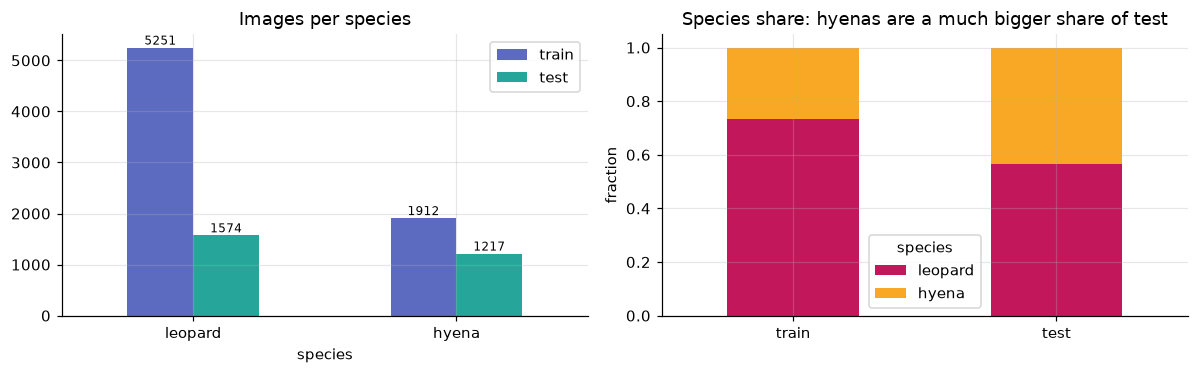

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
c = pd.DataFrame({'train': train.species.value_counts(), 'test': test.species.value_counts()})
c.plot.bar(ax=ax[0], color=['#5c6bc0', '#26a69a'], rot=0); ax[0].set_title('Images per species')
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=8)
(c / c.sum()).T.plot.bar(stacked=True, ax=ax[1], color=[COL['hyena'], COL['leopard']], rot=0)
ax[1].set_title('Species share: hyenas are a much bigger share of test'); ax[1].set_ylabel('fraction')
plt.tight_layout(); plt.show()

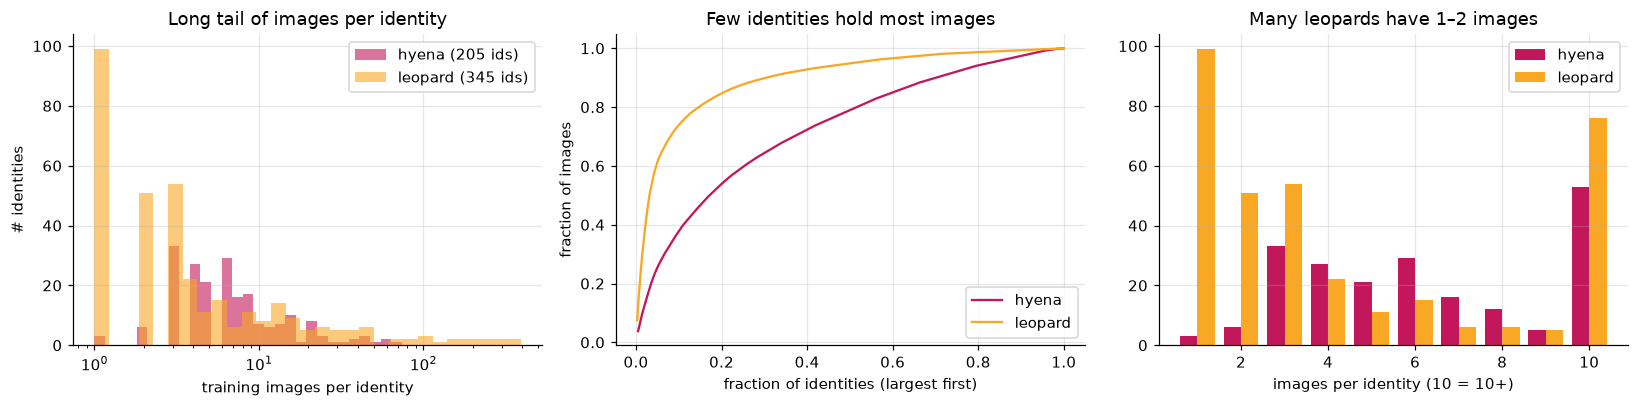

hyena: 205 ids | singletons 3 | <=2 imgs 9 | median 6 | top-5 ids hold 15% of images
leopard: 345 ids | singletons 99 | <=2 imgs 150 | median 3 | top-5 ids hold 30% of images


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for s in ['hyena', 'leopard']:
    vc = train[train.species == s].identity.value_counts()
    ax[0].hist(vc, bins=np.logspace(0, np.log10(vc.max()+1), 30), alpha=.6, color=COL[s], label=f'{s} ({len(vc)} ids)')
    v = np.sort(vc.values)[::-1]; ax[1].plot(np.arange(1, len(v)+1)/len(v), np.cumsum(v)/v.sum(), color=COL[s], label=s)
    k = vc.clip(upper=10).value_counts().sort_index()
    ax[2].bar(k.index + (-.2 if s == 'hyena' else .2), k.values, width=.4, color=COL[s], label=s)
ax[0].set_xscale('log'); ax[0].set_xlabel('training images per identity'); ax[0].set_ylabel('# identities'); ax[0].legend(); ax[0].set_title('Long tail of images per identity')
ax[1].set_xlabel('fraction of identities (largest first)'); ax[1].set_ylabel('fraction of images'); ax[1].set_title('Few identities hold most images'); ax[1].legend()
ax[2].set_xlabel('images per identity (10 = 10+)'); ax[2].set_title('Many leopards have 1–2 images'); ax[2].legend()
plt.tight_layout(); plt.show()
for s in ['hyena', 'leopard']:
    vc = train[train.species == s].identity.value_counts()
    print(f"{s}: {len(vc)} ids | singletons {(vc==1).sum()} | <=2 imgs {(vc<=2).sum()} | median {vc.median():.0f} | top-5 ids hold {vc.head(5).sum()/vc.sum():.0%} of images")

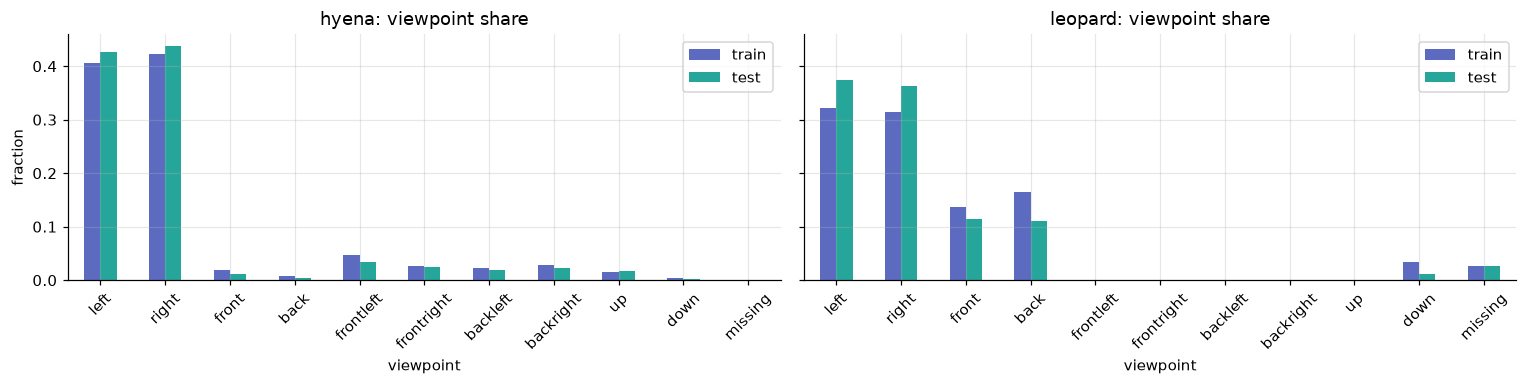

         count      mean       std  min  25%  50%  75%   max
species                                                     
hyena    205.0  2.770732  1.442058  1.0  2.0  2.0  3.0  10.0
leopard  345.0  2.266667  1.359149  1.0  1.0  2.0  3.0   6.0


In [4]:
order = ['left', 'right', 'front', 'back', 'frontleft', 'frontright', 'backleft', 'backright', 'up', 'down', 'missing']
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), sharey=True)
for a, s in zip(ax, ['hyena', 'leopard']):
    t = pd.DataFrame({'train': train[train.species == s].viewpoint.value_counts(normalize=True),
                      'test': test[test.species == s].viewpoint.value_counts(normalize=True)}).reindex(order).fillna(0)
    t.plot.bar(ax=a, color=['#5c6bc0', '#26a69a'], rot=45); a.set_title(f'{s}: viewpoint share'); a.set_ylabel('fraction')
plt.tight_layout(); plt.show()
# how many viewpoints does each identity have in train?
nv = train.groupby(['species', 'identity']).viewpoint.nunique()
print(nv.groupby('species').describe())

**Reading:** test is mostly left/right flanks, more so than train (train has many back/front
views, especially leopards). Left and right flanks of one animal have *different* spot
patterns, so a test left-flank may only match training left-flanks of that individual —
viewpoint should probably be used when ranking (Section 2 checks this).

## 2. MiewID global descriptors

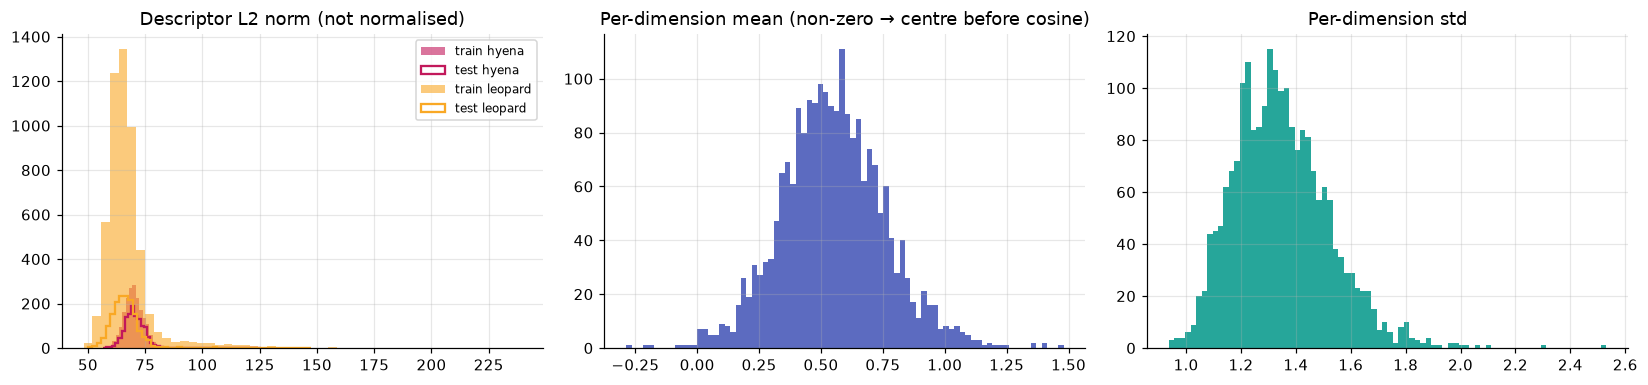

min/max value -4.2377086 32.934937 | exact zeros 0.0


In [5]:
norms = np.linalg.norm(X, axis=1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for s in ['hyena', 'leopard']:
    ax[0].hist(np.linalg.norm(Xtr[train.species == s], axis=1), bins=50, alpha=.6, color=COL[s], label=f'train {s}')
    ax[0].hist(np.linalg.norm(Xte[test.species == s], axis=1), bins=50, histtype='step', color=COL[s], lw=1.5, label=f'test {s}')
ax[0].set_title('Descriptor L2 norm (not normalised)'); ax[0].legend(fontsize=8)
ax[1].hist(X.mean(0), bins=80, color='#5c6bc0'); ax[1].set_title('Per-dimension mean (non-zero → centre before cosine)')
ax[2].hist(X.std(0), bins=80, color='#26a69a'); ax[2].set_title('Per-dimension std')
plt.tight_layout(); plt.show()
print('min/max value', X.min(), X.max(), '| exact zeros', (X == 0).mean().round(4))

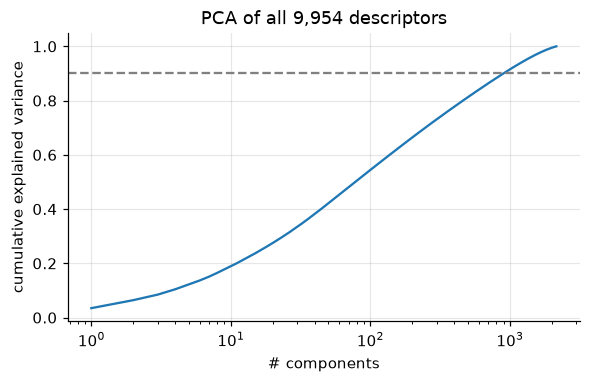

{0.5: 78, 0.8: 461, 0.9: 898, 0.95: 1302}


In [6]:
pca = PCA(random_state=0).fit(X)
ev = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(6, 3.4)); plt.plot(np.arange(1, len(ev)+1), ev); plt.xscale('log'); plt.axhline(.9, ls='--', c='gray')
plt.xlabel('# components'); plt.ylabel('cumulative explained variance'); plt.title('PCA of all 9,954 descriptors'); plt.show()
print({k: int(np.searchsorted(ev, k)+1) for k in [.5, .8, .9, .95]})

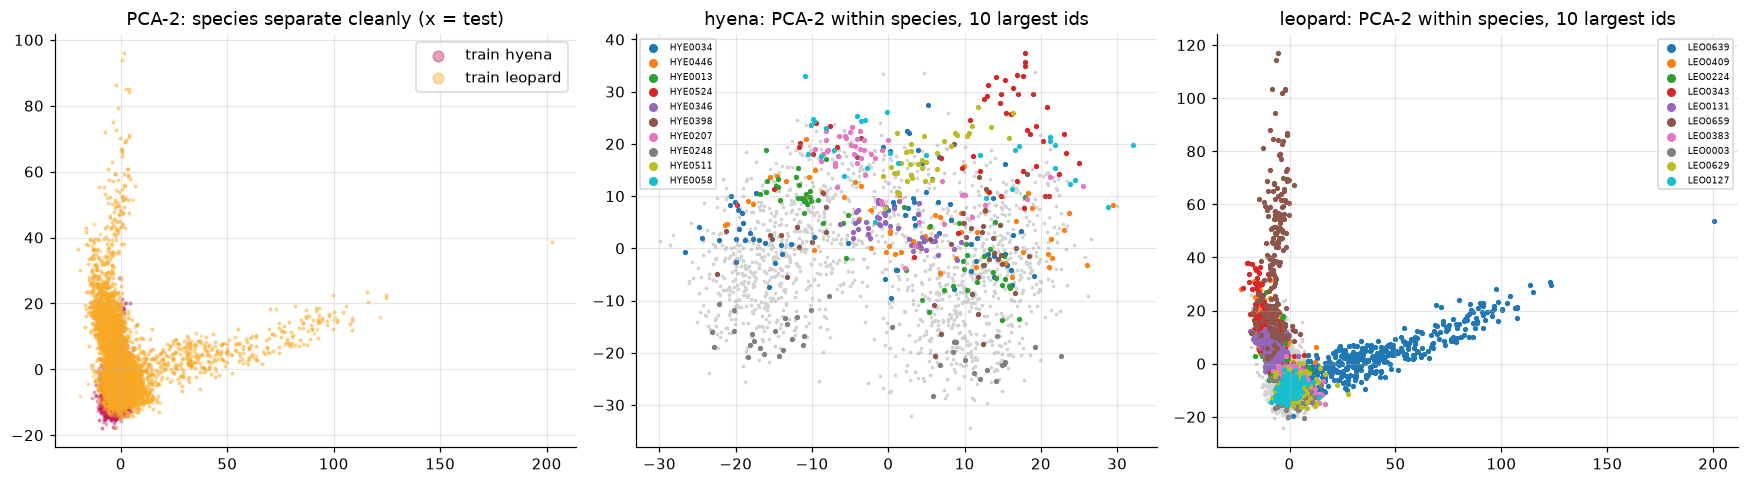

In [7]:
Z = pca.transform(X)[:, :2]
Ztr = Z[[row[i] for i in train.id]]; Zte = Z[[row[i] for i in test.id]]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for s in ['hyena', 'leopard']:
    m = (train.species == s).values; ax[0].scatter(*Ztr[m].T, s=3, alpha=.4, c=COL[s], label=f'train {s}')
    m = (test.species == s).values;  ax[0].scatter(*Zte[m].T, s=3, alpha=.4, c=COL[s], marker='x')
ax[0].legend(markerscale=4); ax[0].set_title('PCA-2: species separate cleanly (x = test)')
for a, s in zip(ax[1:], ['hyena', 'leopard']):
    sub = train[train.species == s]; Xs = Xtr[(train.species == s).values]
    Zs = PCA(2, random_state=0).fit_transform(Xs - Xs.mean(0))
    top = sub.identity.value_counts().index[:10]
    a.scatter(*Zs.T, s=2, c='lightgray')
    for j, idn in enumerate(top):
        m = (sub.identity == idn).values; a.scatter(*Zs[m].T, s=6, color=plt.cm.tab10(j), label=idn)
    a.set_title(f'{s}: PCA-2 within species, 10 largest ids'); a.legend(fontsize=6, markerscale=2)
plt.tight_layout(); plt.show()

Linear PCA-2 doesn't separate individuals (expected — identity lives in many dimensions), so
2-D plots understate how good the descriptor is. The real test is pairwise similarity:

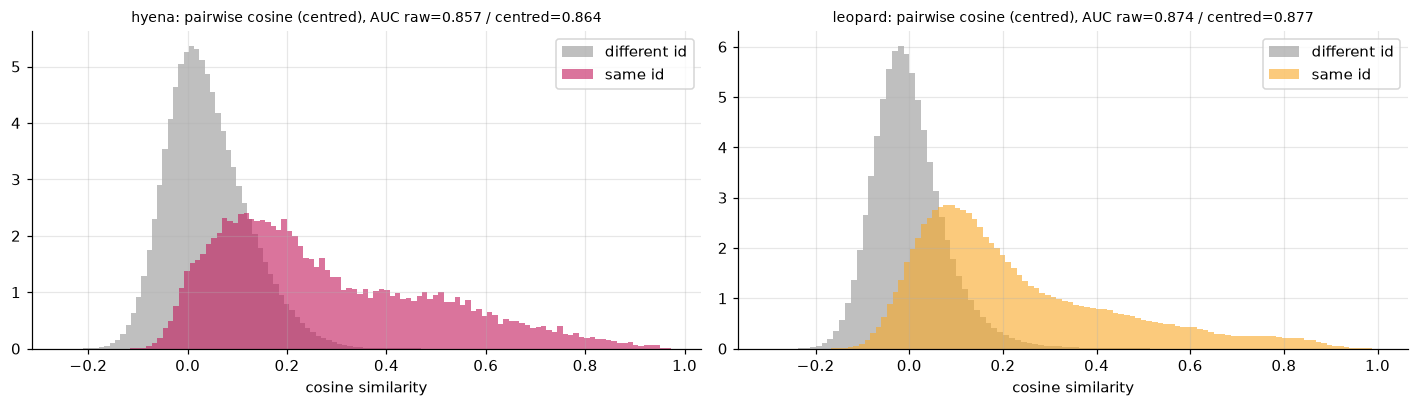

In [8]:
def l2n(A): return A / np.linalg.norm(A, axis=1, keepdims=True).clip(1e-12)
mu = Xtr.mean(0)
variants = {'raw cosine': l2n(Xtr), 'centred + L2': l2n(Xtr - mu)}
sp = train.species.values; idn = train.identity.values; vp = train.viewpoint.values
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
pair_stats = {}
for a, s in zip(ax, ['hyena', 'leopard']):
    m = np.where(sp == s)[0]
    for name, F in variants.items():
        S = F[m] @ F[m].T; iu = np.triu_indices(len(m), 1); sims = S[iu]
        same = idn[m][iu[0]] == idn[m][iu[1]]
        auc = roc_auc_score(same, sims); pair_stats[(s, name)] = auc
        if name == 'centred + L2':
            a.hist(sims[~same], bins=100, density=True, alpha=.5, color='gray', label='different id')
            a.hist(sims[same], bins=100, density=True, alpha=.6, color=COL[s], label='same id')
    a.set_title(f'{s}: pairwise cosine (centred), AUC raw={pair_stats[(s,"raw cosine")]:.3f} / centred={pair_stats[(s,"centred + L2")]:.3f}', fontsize=9)
    a.legend(); a.set_xlabel('cosine similarity')
plt.tight_layout(); plt.show()

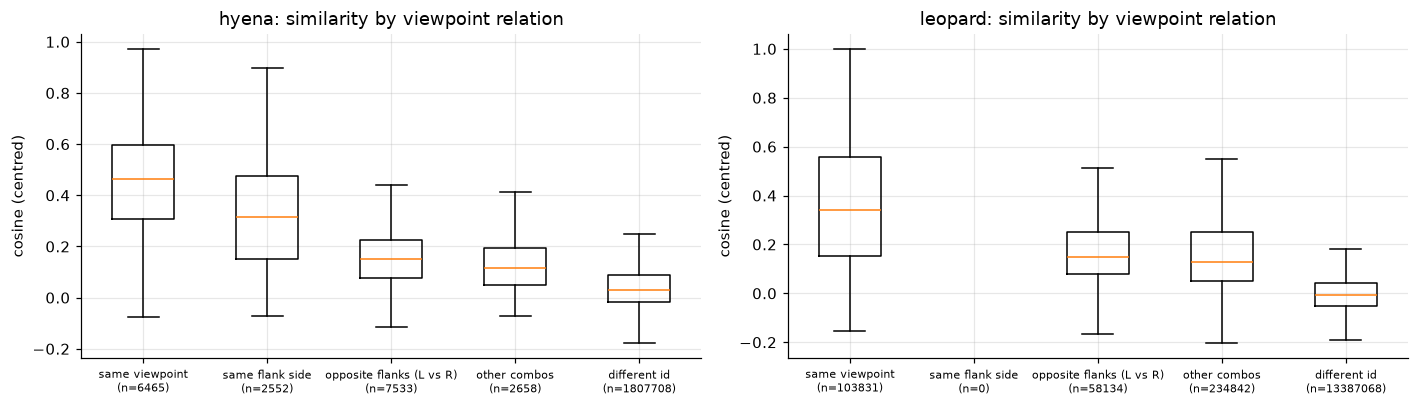

In [9]:
# Does viewpoint matter? same-identity similarity split by viewpoint relation
F = variants['centred + L2']
side = {'left': 'L', 'frontleft': 'L', 'backleft': 'L', 'right': 'R', 'frontright': 'R', 'backright': 'R'}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, s in zip(ax, ['hyena', 'leopard']):
    m = np.where(sp == s)[0]; S = F[m] @ F[m].T; iu = np.triu_indices(len(m), 1)
    same = idn[m][iu[0]] == idn[m][iu[1]]; sims = S[iu]
    v1, v2 = vp[m][iu[0]], vp[m][iu[1]]
    s1 = np.array([side.get(v, 'O') for v in v1]); s2 = np.array([side.get(v, 'O') for v in v2])
    groups = {'same viewpoint': same & (v1 == v2),
              'same flank side': same & (s1 == s2) & (s1 != 'O') & (v1 != v2),
              'opposite flanks (L vs R)': same & (((s1 == 'L') & (s2 == 'R')) | ((s1 == 'R') & (s2 == 'L'))),
              'other combos': same & ~((v1 == v2) | ((s1 != 'O') & (s2 != 'O'))),
              'different id': ~same}
    data = [sims[g] for g in groups.values()]
    a.boxplot(data, showfliers=False); a.set_xticks(range(1, 6), [f'{k}\n(n={g.sum()})' for k, g in groups.items()], fontsize=7)
    a.set_title(f'{s}: similarity by viewpoint relation'); a.set_ylabel('cosine (centred)')
plt.tight_layout(); plt.show()

If the "opposite flanks" box sits near the "different id" box, an individual seen only from the
left in train can't be matched from a right-flank test image by descriptor alone — a key
reason for `new_individual` false alarms and for using viewpoint as a feature.

## 3. Retrieval baseline (leave-one-out on train) and `new_individual`

In [10]:
def map5(preds, truth):
    tot = 0.
    for p, t in zip(preds, truth):
        for k, lab in enumerate(p[:5]):
            if lab == t: tot += 1/(k+1); break
    return tot / len(truth)

loo = []  # per query: ranked identities (by max similarity), their scores, truth, is_new
for s in ['hyena', 'leopard']:
    m = np.where(sp == s)[0]; S = F[m] @ F[m].T; np.fill_diagonal(S, -np.inf)
    labs = idn[m]; uniq, inv = np.unique(labs, return_inverse=True)
    # max similarity to each identity
    M = np.full((len(m), len(uniq)), -np.inf)
    for j in range(len(uniq)): M[:, j] = S[:, inv == j].max(1)
    cnt = np.bincount(inv)
    for q in range(len(m)):
        o = np.argsort(-M[q])[:5]
        loo.append(dict(species=s, truth=labs[q], is_new=cnt[inv[q]] == 1, top=uniq[o], score=M[q, o],
                        rank=(np.where(uniq[np.argsort(-M[q])] == labs[q])[0][0] + 1)))
loo = pd.DataFrame(loo)
known = loo[~loo.is_new]
print('LOO queries:', len(loo), '| whose identity has no other train image (would be new):', loo.is_new.sum())
for s, g in known.groupby('species'):
    print(f"{s}: top-1 {np.mean(g['rank']==1):.3f} | top-5 {np.mean(g['rank']<=5):.3f} | MAP@5 (known only) {map5(g.top.tolist(), g.truth.tolist()):.3f}")

LOO queries: 7163 | whose identity has no other train image (would be new): 102
hyena: top-1 0.851 | top-5 0.918 | MAP@5 (known only) 0.878
leopard: top-1 0.866 | top-5 0.921 | MAP@5 (known only) 0.888


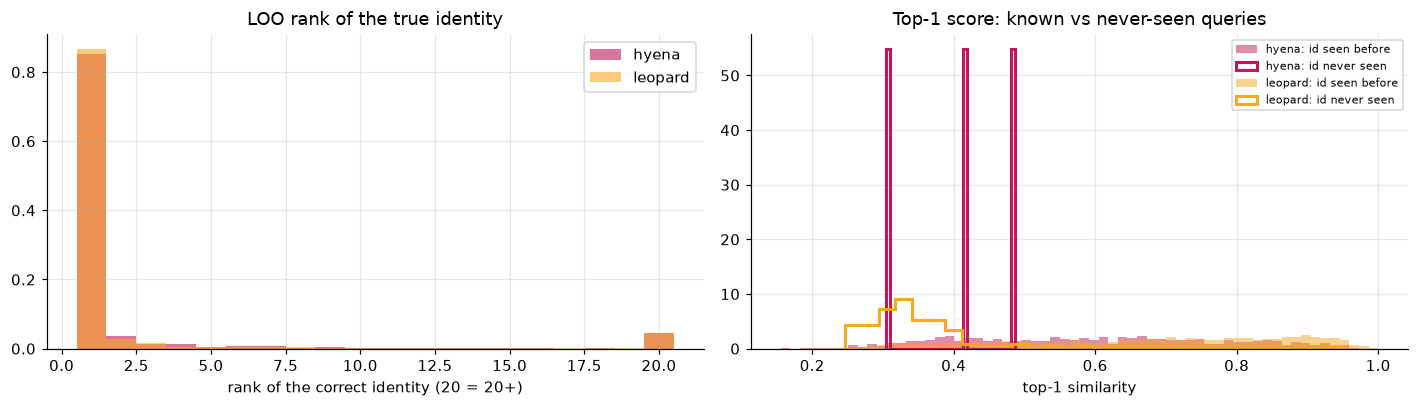

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for s in ['hyena', 'leopard']:
    g = known[known.species == s]; r = g['rank'].clip(upper=20)
    ax[0].hist(r, bins=np.arange(1, 22)-.5, alpha=.6, color=COL[s], density=True, label=s)
    ax[1].hist(loo[(loo.species == s) & ~loo.is_new].score.str[0], bins=60, density=True, alpha=.5, color=COL[s], label=f'{s}: id seen before')
    ax[1].hist(loo[(loo.species == s) & loo.is_new].score.str[0], bins=30, density=True, histtype='step', lw=2, color=COL[s], label=f'{s}: id never seen')
ax[0].set_xlabel('rank of the correct identity (20 = 20+)'); ax[0].set_title('LOO rank of the true identity'); ax[0].legend()
ax[1].set_xlabel('top-1 similarity'); ax[1].set_title('Top-1 score: known vs never-seen queries'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

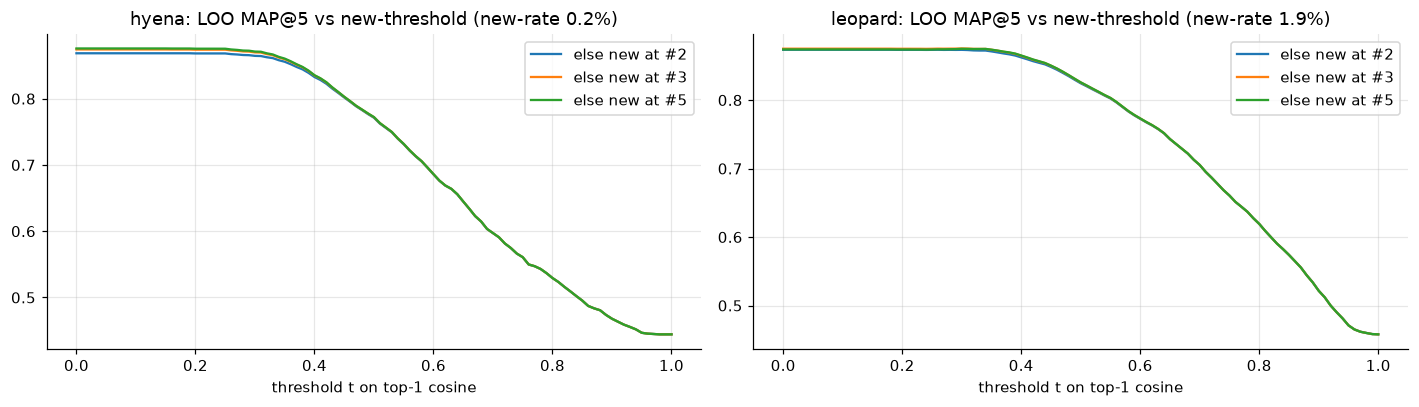

In [12]:
# Where should new_individual go? Simple rule: put it first if top-1 score < t, else at position `pos`.
def with_new(top, score, t, pos):
    top = list(top)
    return ['new_individual'] + top[:4] if score[0] < t else top[:pos-1] + ['new_individual'] + top[pos-1:4]
ts = np.linspace(0, 1, 101)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, s in zip(ax, ['hyena', 'leopard']):
    g = loo[loo.species == s]; truth = np.where(g.is_new, 'new_individual', g.truth)
    for pos in [2, 3, 5]:
        a.plot(ts, [map5([with_new(t_, sc, t, pos) for t_, sc in zip(g.top, g.score)], truth) for t in ts], label=f'else new at #{pos}')
    a.set_title(f'{s}: LOO MAP@5 vs new-threshold (new-rate {g.is_new.mean():.1%})'); a.set_xlabel('threshold t on top-1 cosine'); a.legend()
plt.tight_layout(); plt.show()

Caveat: in LOO only train singletons act as "new", so the new-rate here (~2% hyena, a few %
leopard) is far below what test probably has. The *shape* (an interior optimum, and the value of
putting `new_individual` at #2 rather than dropping it) is the useful part; the threshold must be
tuned on a split that holds out whole identities (D-003).

## 4. Test vs train: how known do the test images look?

hyena test top-1 median 0.436 | train-LOO known median 0.595


leopard test top-1 median 0.459 | train-LOO known median 0.703


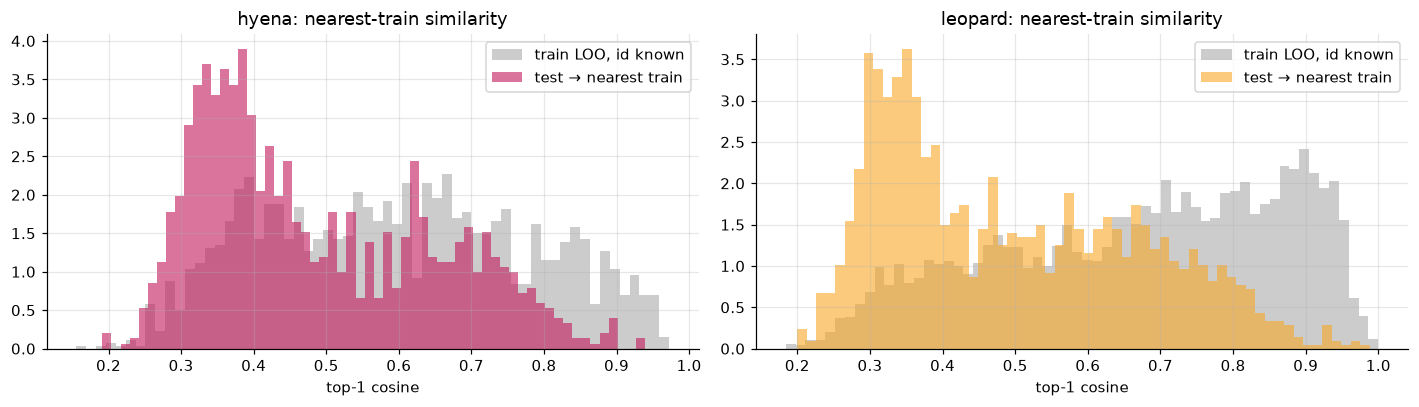

In [13]:
Fte = l2n(Xte - mu)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, s in zip(ax, ['hyena', 'leopard']):
    mtr = sp == s; mte = (test.species == s).values
    top_te = (Fte[mte] @ F[mtr].T).max(1)
    g = loo[loo.species == s]
    a.hist(g[~g.is_new].score.str[0], bins=60, density=True, alpha=.4, color='gray', label='train LOO, id known')
    a.hist(top_te, bins=60, density=True, alpha=.6, color=COL[s], label='test → nearest train')
    a.set_title(f'{s}: nearest-train similarity'); a.set_xlabel('top-1 cosine'); a.legend()
    print(s, 'test top-1 median', np.median(top_te).round(3), '| train-LOO known median', np.median(g[~g.is_new].score.str[0]).round(3))
plt.tight_layout(); plt.show()

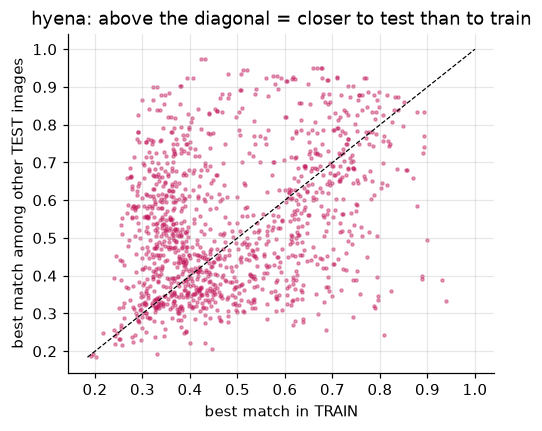

hyena: 44.6% of test images are clearly closer to another test image than to any train image


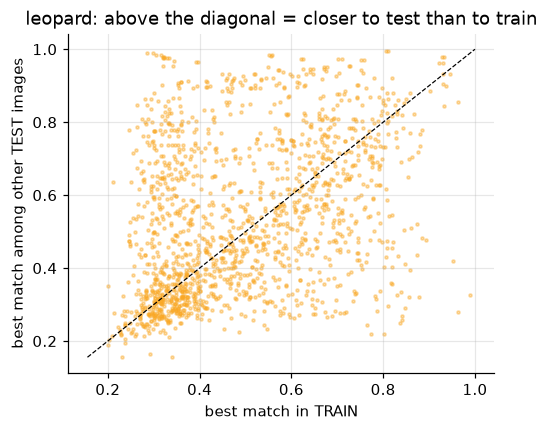

leopard: 38.6% of test images are clearly closer to another test image than to any train image


In [14]:
# Test images that look like each other but not like train → candidate clusters of new individuals
from scipy.cluster.hierarchy import linkage, fcluster
for s in ['hyena', 'leopard']:
    mtr = sp == s; mte = (test.species == s).values
    top_te = (Fte[mte] @ F[mtr].T).max(1)
    tt = Fte[mte] @ Fte[mte].T; np.fill_diagonal(tt, -1); top_tt = tt.max(1)
    plt.figure(figsize=(5, 4)); plt.scatter(top_te, top_tt, s=4, alpha=.4, c=COL[s])
    lim = [min(top_te.min(), top_tt.min()), 1]; plt.plot(lim, lim, 'k--', lw=.8)
    plt.xlabel('best match in TRAIN'); plt.ylabel('best match among other TEST images')
    plt.title(f'{s}: above the diagonal = closer to test than to train'); plt.show()
    print(f'{s}: {np.mean(top_tt > top_te + .05):.1%} of test images are clearly closer to another test image than to any train image')

## 5. SIFT keypoints

1.4s


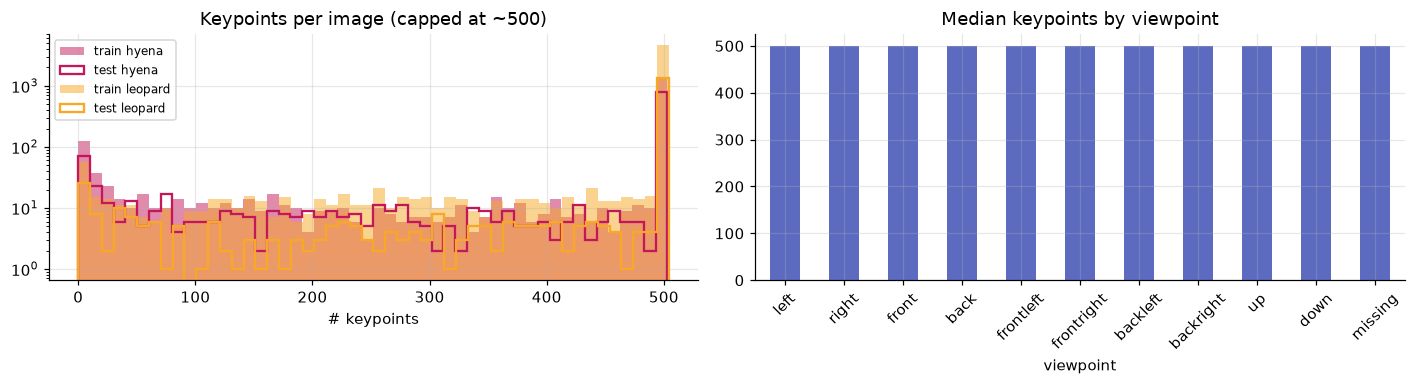

train | 0 kp: 61 | <50: 4.4% | <500: 17.8%
test | 0 kp: 35 | <50: 6.3% | <500: 23.0%


In [15]:
SIFT = {'train': D / 'sift_features_train.npz', 'test': D / 'sift_features_test.npz'}
def load_sift(split, i):
    p = SIFT[split]
    if p.is_dir(): return np.load(p / f'{i}_xy.npy'), np.load(p / f'{i}_desc.npy')
    z = np.load(p); return z[f'{i}_xy'], z[f'{i}_desc']
t0 = time.time()
nkp_tr = np.array([np.load(SIFT['train'] / f'{i}_xy.npy', mmap_mode='r').shape[0] for i in train.id])
nkp_te = np.array([np.load(SIFT['test'] / f'{i}_xy.npy', mmap_mode='r').shape[0] for i in test.id])
train['nkp'] = nkp_tr; test['nkp'] = nkp_te; print(f'{time.time()-t0:.1f}s')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for s in ['hyena', 'leopard']:
    ax[0].hist(train[train.species == s].nkp, bins=50, alpha=.5, color=COL[s], label=f'train {s}')
    ax[0].hist(test[test.species == s].nkp, bins=50, histtype='step', lw=1.5, color=COL[s], label=f'test {s}')
ax[0].set_yscale('log'); ax[0].set_xlabel('# keypoints'); ax[0].legend(fontsize=8); ax[0].set_title('Keypoints per image (capped at ~500)')
train.groupby('viewpoint').nkp.median().reindex(order).plot.bar(ax=ax[1], color='#5c6bc0', rot=45); ax[1].set_title('Median keypoints by viewpoint')
plt.tight_layout(); plt.show()
for n, d in [('train', train), ('test', test)]:
    print(n, '| 0 kp:', (d.nkp == 0).sum(), '| <50:', f'{(d.nkp < 50).mean():.1%}', '| <500:', f'{(d.nkp < 500).mean():.1%}')

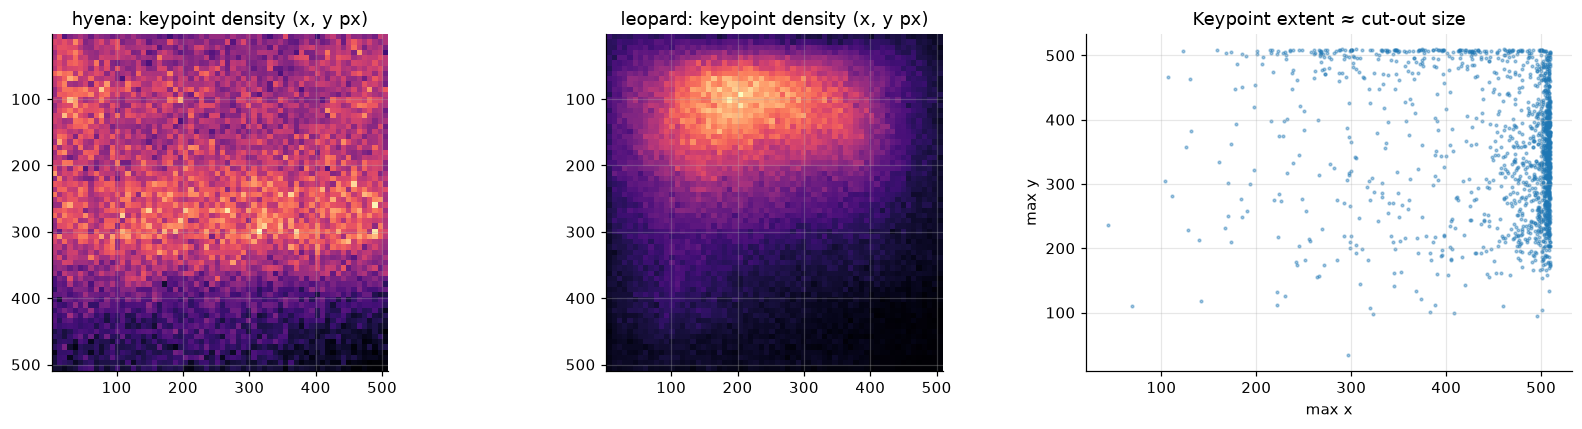

In [16]:
# Where do keypoints sit? (pixel coords of the cut-out; longer side <= 512)
sample = rng.choice(len(train), 1500, replace=False)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, s in zip(ax[:2], ['hyena', 'leopard']):
    pts = np.vstack([load_sift('train', i)[0] for i in train.id.values[sample][train.species.values[sample] == s]])
    a.hist2d(pts[:, 0], pts[:, 1], bins=64, cmap='magma'); a.invert_yaxis(); a.set_title(f'{s}: keypoint density (x, y px)'); a.set_aspect('equal')
ext = np.array([load_sift('train', i)[0].max(0) if n > 0 else [np.nan, np.nan] for i, n in zip(train.id.values[sample], nkp_tr[sample])])
ax[2].scatter(ext[:, 0], ext[:, 1], s=3, alpha=.4); ax[2].set_xlabel('max x'); ax[2].set_ylabel('max y'); ax[2].set_title('Keypoint extent ≈ cut-out size')
plt.tight_layout(); plt.show()

600 pairs in 2s


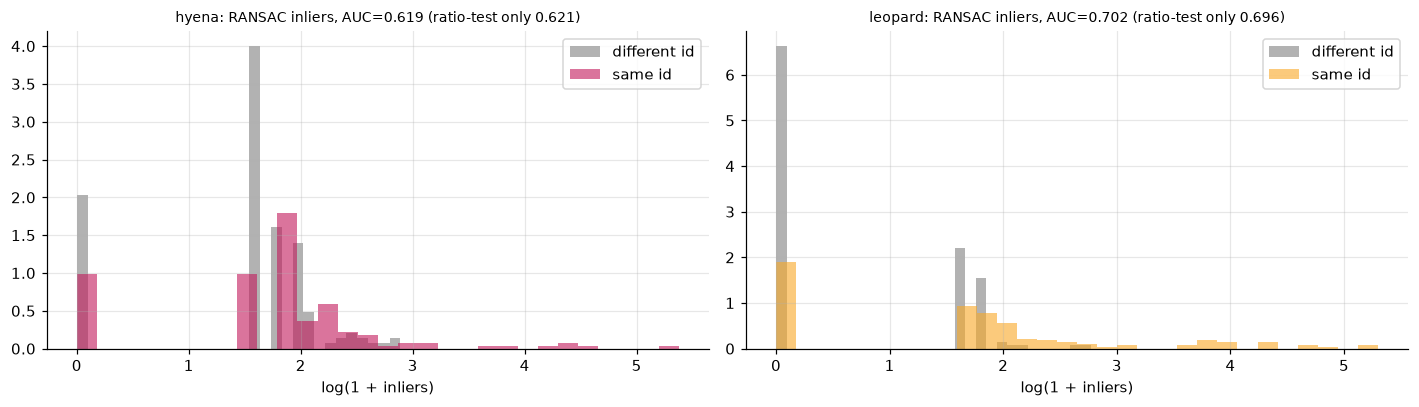

In [17]:
# How well does classical SIFT matching separate identities? Sample same-id and different-id pairs.
bf = cv2.BFMatcher(cv2.NORM_L2)
def match_score(a, b, ratio=.8):
    (xa, da), (xb, db) = load_sift('train', a), load_sift('train', b)
    if len(da) < 2 or len(db) < 2: return 0, 0
    m = bf.knnMatch(da.astype(np.float32), db.astype(np.float32), k=2)
    good = [p[0] for p in m if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    if len(good) < 5: return len(good), 0
    src = xa[[g.queryIdx for g in good]]; dst = xb[[g.trainIdx for g in good]]
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 10.0)
    return len(good), int(mask.sum()) if mask is not None else 0

pairs = []
for s in ['hyena', 'leopard']:
    sub = train[(train.species == s) & (train.nkp >= 20)]
    g = sub.groupby('identity').id.apply(list); g = g[g.str.len() >= 2]
    for _ in range(150):
        a, b = rng.choice(g.iloc[rng.integers(len(g))], 2, replace=False); pairs.append((s, a, b, 1))
        a, b = sub.sample(2, random_state=int(rng.integers(1e9))).id.values
        pairs.append((s, a, b, int(sub.set_index('id').identity[a] == sub.set_index('id').identity[b])))
t0 = time.time()
res = pd.DataFrame([(s, y, *match_score(a, b)) for s, a, b, y in pairs], columns=['species', 'same', 'ratio_matches', 'ransac_inliers'])
print(f'{len(res)} pairs in {time.time()-t0:.0f}s')
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, s in zip(ax, ['hyena', 'leopard']):
    r = res[res.species == s]
    for y, c, lab in [(0, 'gray', 'different id'), (1, COL[s], 'same id')]:
        a.hist(np.log1p(r[r.same == y].ransac_inliers), bins=30, alpha=.6, color=c, label=lab, density=True)
    auc_r = roc_auc_score(r.same, r.ransac_inliers); auc_m = roc_auc_score(r.same, r.ratio_matches)
    a.set_title(f'{s}: RANSAC inliers, AUC={auc_r:.3f} (ratio-test only {auc_m:.3f})', fontsize=9); a.set_xlabel('log(1 + inliers)'); a.legend()
plt.tight_layout(); plt.show()

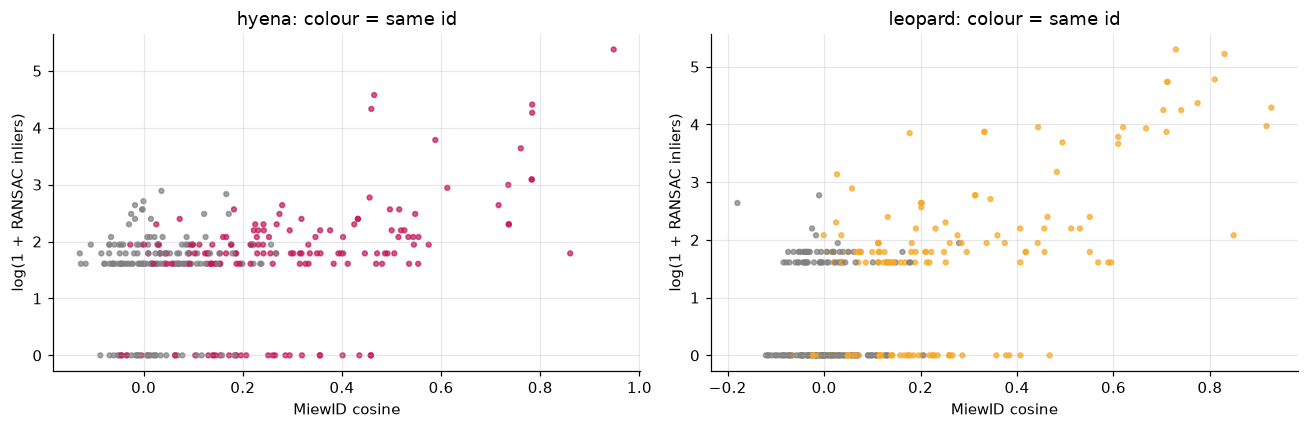

In [18]:
# Do SIFT and MiewID disagree? (useful if we want to combine them)
fid = {k: i for i, k in enumerate(train.id)}
res['miewid'] = [float(F[fid[a]] @ F[fid[b]]) for s, a, b, y in pairs]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, s in zip(ax, ['hyena', 'leopard']):
    r = res[res.species == s]
    a.scatter(r.miewid, np.log1p(r.ransac_inliers), c=np.where(r.same, COL[s], 'gray'), s=10, alpha=.7)
    a.set_xlabel('MiewID cosine'); a.set_ylabel('log(1 + RANSAC inliers)'); a.set_title(f'{s}: colour = same id')
plt.tight_layout(); plt.show()

## 6. Takeaways

Numbers below are from the run committed on 2026-11-22.

- **The big one: test looks far less "known" than train.** Median nearest-train cosine for test
  is 0.44 (hyena) / 0.46 (leopard), vs 0.60 / 0.70 for train images whose identity has other
  train images. Test has a large mode around 0.3–0.4, exactly where never-seen identities sit.
  ~45% of hyena and ~39% of leopard test images are clearly closer to another test image than
  to any train image. **A large share of test (plausibly 30–50%) is `new_individual`**, so the
  new-individual decision probably matters more than the ranking of known ids.

- **Two separate problems.** Species never mix (given in test), so build everything per species.
  Hyenas: fewer, better-sampled identities. Leopards: long tail, ~100 singletons.
- **Test ≠ train in distribution.** Much higher hyena share, more left/right flanks. New
  individuals come in groups in test → clustering test images is worth trying.
- **MiewID is strong on known ids.** Leave-one-out cosine k-NN (centred + L2, max-sim per
  identity): top-1 0.85 / 0.87, top-5 0.92 / 0.92, MAP@5 0.88 / 0.89 (hyena / leopard), known
  ids only. Centring helps slightly (pair AUC 0.857→0.864 hyena, 0.874→0.877 leopard). Most of the remaining score is in
  (a) the `new_individual` decision, and (b) hard cases: opposite flanks, rare viewpoints.
- **Viewpoint matters.** Same-id median cosine is ~0.46 (hyena) / ~0.34 (leopard) for the same
  viewpoint but ~0.15 across left/right flanks — close to different-id (~0.03 / 0.0). Same-id
  pairs from opposite flanks look almost like strangers, so ranking
  should prefer matches with compatible viewpoints and the new-threshold may depend on it.
- **SIFT as first tried is weak** (pair AUC 0.62 hyena / 0.70 leopard on random pairs, vs
  0.86 / 0.88 for MiewID). It used a homography with 10 px RANSAC, which suits flat scenes, not
  bending animals; the spike at 4 inliers is the homography minimum. Worth retrying with a
  fundamental matrix / affine model, mutual-NN matching, and a min-inlier cutoff before
  judging it. It may still help re-rank close MiewID calls, and gives nothing for the 4–6% of
  images with <50 keypoints (61 train / 35 test have none).
- **Validation:** LOO-on-train hides the new-individual problem (only singletons act as new).
  Use an identity-held-out split (D-003).

## 7. Models to try (all within the allowed list), roughly in order

| # | Model | What it does here | Why it should help |
|---|---|---|---|
| 1 | **Cosine k-NN retrieval** on centred, L2-normed MiewID (per species), score per identity = max (or top-k mean) similarity | Baseline ranking of identities | MiewID was trained for re-ID; same-id pairs already separate well. Cheap, no training. |
| 2 | **Threshold rule for `new_individual`** on top-1 score (and margin top1−top2), tuned per species on an identity-held-out split | Decides *where* to put `new_individual` (#1 vs #2…#5) | The new decision is a big part of MAP@5; putting it at #2 when unsure costs only half a point. |
| 3 | **PCA whitening / LDA projection** of descriptors before cosine | Linear metric learning: LDA maximises between-id vs within-id variance | Allowed "linear projection metric learning"; LDA uses identity labels directly and usually sharpens retrieval. Keep dims < #ids. |
| 4 | **Linear metric learning** (e.g. NCA in scikit-learn, or a learned Mahalanobis via LDA+whitening) | Learns a linear map so same-id neighbours are closer | Explicitly allowed (linear); can down-weight viewpoint-related directions. |
| 5 | **Query expansion / k-reciprocal re-ranking** (average query with its top neighbours, Jaccard of reciprocal neighbour sets) | Distance-based re-ranking | Classic retrieval trick, pure k-NN/distance logic; strong with multi-image identities. |
| 6 | **SIFT ratio test + RANSAC re-ranking** of the top-N MiewID candidates | Geometric verification of shared spots | Independent evidence (local pattern vs global embedding); the scatter in §5 shows cases where they disagree. |
| 7 | **Learned score fusion / "is-same" classifier**: logistic regression or LightGBM/HistGradientBoosting on pair features (MiewID cosine, rank, margin, RANSAC inliers, ratio matches, keypoint counts, viewpoint match flags, #train images of the candidate id) | Turns several signals into one calibrated match probability; also predicts P(new) | Gradient boosting & logistic regression are allowed; calibrated probabilities make the new-individual placement principled. |
| 8 | **Test-set clustering** (agglomerative / graph clustering with networkx connected components on a high-similarity graph) | Groups test images that are the same unseen animal | New individuals recur in test; if a cluster has no confident train match, label all of them new; if one member matches confidently, propagate. |
| 9 | **Per-identity classifiers**: logistic/softmax regression, linear SVM, LDA/QDA-style Gaussian class models on (projected) descriptors | Classification instead of retrieval | Works for well-sampled identities (hyenas, big leopards); weak for singletons — use as an extra signal in fusion, not alone. |
| 10 | **Gaussian mixture / KDE open-set scoring** | Density of "known" region per identity / per species | Gives a likelihood for "this belongs to no known identity", another feature for the new decision. |
| 11 | **Small MLP (sklearn `MLPClassifier`)** on pair features or as a fusion model | Non-linear fusion | Allowed; only if boosting/logistic plateau. Watch overfitting. |
| 12 | **Ensembling / stacking** of 1–9 | Combine ranked lists or probabilities | Simple model combination is allowed and usually stabilises the private-LB score. |

Not allowed (don't try): CNNs/transformers, PyTorch/TF, pre-trained models, features computed
from the images (D-005), AutoML.